# SupportGen · 03 — Fine-tuning FLAN-T5 on customer-support conversations (Model B)
This is the **core Generative AI contribution** of the project: we take the pretrained
encoder-decoder Transformer `google/flan-t5-small` (~77M parameters) and continue training **all of
its weights** on our ticket → agent-answer pairs, so that it learns to generate domain-specific
support responses.

**What is being learned?** Conditional text generation: P(answer | subject, ticket).

**Runtime:** GPU (`Runtime → Change runtime type → T4 GPU` or better).
The actual training time is measured and saved; FLAN-T5-base takes several times longer than small.

## 0. Setup — Google Drive & project folder
Every SupportGen notebook starts with this same cell. It mounts Google Drive so that all
notebooks share one project folder (`MyDrive/SupportGen`): notebook 01 writes the cleaned
splits there, notebooks 02–06 read them. Nothing ever needs to be uploaded from your laptop.

Set `USE_DRIVE = False` only for a throw-away run — files then live in `/content` and are lost
when the Colab runtime disconnects.

In [1]:
# ── Setup (identical in every SupportGen notebook) ──────────────────────────
USE_DRIVE = True   # False → keep everything in /content (deleted when the runtime ends)

import os, sys
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/SupportGen"
else:
    BASE = "/content/SupportGen"
os.makedirs(BASE, exist_ok=True)
os.environ["SUPPORTGEN_BASE"] = BASE   # read by supportgen_common.py
sys.path.insert(0, BASE)
print("Project folder:", BASE)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/SupportGen


In [2]:

# Colab already ships torch, transformers, accelerate, scikit-learn, pandas, matplotlib.
# These are the extras SupportGen needs (already-installed packages are skipped).
!pip -q install evaluate rouge_score bert_score sacrebleu sentencepiece sentence-transformers

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 12.6 MB/s eta 0:00:00


In [3]:
# Shared helpers were written to Drive by 01_dataset_preparation.ipynb
if not os.path.exists(os.path.join(BASE, "supportgen_common.py")):
    raise FileNotFoundError(
        f"supportgen_common.py not found in {BASE}. Run 01_dataset_preparation.ipynb first "
        "(with the same USE_DRIVE setting).")
import importlib, supportgen_common as sg
importlib.reload(sg)
sg.set_seed()
print("Device:", sg.get_device())

Device: cuda


In [4]:
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo 'No GPU — switch the runtime to GPU'

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Experiment configuration
Change **only this cell** between experiments.

* `QUICK_RUN = True` → 1,000 training examples, 1 epoch: a ~2-minute check that the whole pipeline
  works before spending GPU time on the real run. It saves to a separate folder and never overwrites
  the real model.
* `MODEL_NAME = "google/flan-t5-base"` → optional **Model D** (~248M parameters).

**Why these hyper-parameters?**
* `learning_rate = 3e-4` — T5 models are commonly fine-tuned with larger learning rates than BERT-style
  models (1e-4 – 1e-3 range); 3e-4 with AdamW is a standard, conservative choice.
* `epochs = 4` with **early stopping on validation loss** (patience 2) — stops if the model starts
  overfitting; the best epoch (lowest validation loss) is kept.
* `weight_decay = 0.01`, linear schedule with 5 % warm-up — standard regularisation and a stable start.
* **Precision:** T5 is known to overflow (NaN loss) in fp16, so we use **bf16** on Ampere+ GPUs (A100/L4)
  and plain fp32 on a T4.

In [5]:
MODEL_NAME = sg.BASE_MODEL           # or "google/flan-t5-base" for experiment D
QUICK_RUN = False                    # True = fast pipeline check on 1,000 examples
CKPT_ON_DRIVE = False                # True = keep per-epoch checkpoints on Drive (survive disconnects, use more space)

is_small = "small" in MODEL_NAME
HP = dict(
    learning_rate=3e-4,
    num_train_epochs=4,
    per_device_train_batch_size=16 if is_small else 8,
    gradient_accumulation_steps=1 if is_small else 2,      # effective batch size 16 in both cases
    per_device_eval_batch_size=32 if is_small else 16,
    weight_decay=0.01,
    warmup_fraction=0.05,
    early_stopping_patience=2,
)
RUN_NAME = sg.RUN_FT if is_small else sg.RUN_FT_BASE
OUTPUT_DIR = sg.FINETUNED_DIR if is_small else sg.FINETUNED_BASE_DIR
if QUICK_RUN:
    RUN_NAME += "_quick"; OUTPUT_DIR += "-quick"; HP["num_train_epochs"] = 1
CKPT_DIR = (os.path.join(BASE, "checkpoints", RUN_NAME) if CKPT_ON_DRIVE else f"/content/checkpoints/{RUN_NAME}")

cfg = sg.load_config()
MAX_IN, MAX_OUT = cfg["max_input_len"], cfg["max_target_len"]
print(RUN_NAME, "→", OUTPUT_DIR, "| max lengths", MAX_IN, MAX_OUT, "\n", HP)

B_ft_flan-t5-small → /content/drive/MyDrive/SupportGen/models/flan-t5-supportgen | max lengths 160 128 
 {'learning_rate': 0.0003, 'num_train_epochs': 4, 'per_device_train_batch_size': 16, 'gradient_accumulation_steps': 1, 'per_device_eval_batch_size': 32, 'weight_decay': 0.01, 'warmup_fraction': 0.05, 'early_stopping_patience': 2}


## 2. Load splits and build input/target pairs
Input = prompt template filled with subject + ticket body; target = the agent's real answer.

In [6]:
import numpy as np, pandas as pd, torch, time, json, platform
import transformers
from datasets import Dataset

train_df, val_df, test_df = sg.load_split("train"), sg.load_split("val"), sg.load_split("test")
if QUICK_RUN:
    train_df = train_df.sample(1000, random_state=sg.SEED)
    val_df = val_df.sample(min(200, len(val_df)), random_state=sg.SEED)

def to_ds(d):
    return Dataset.from_dict({"input": [sg.build_prompt(s, b) for s, b in zip(d.subject, d.body)],
                              "target": d.answer.tolist()})
ds = {"train": to_ds(train_df), "val": to_ds(val_df), "test": to_ds(test_df)}
print({k: len(v) for k, v in ds.items()})
print("\nINPUT :", ds["train"][0]["input"][:300])
print("TARGET:", ds["train"][0]["target"][:300])

{'train': 18848, 'val': 2354, 'test': 2339}

INPUT : Generate a professional customer support response.
Subject: Account Disruption
Customer ticket: Dear Customer Support Team, I am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage is blocking access to account se
TARGET: Thank you for reaching out, <name>. We are aware of the outage affecting the centralized account management system, and our technical team is actively working to resolve the issue. In the meantime, we suggest using alternative methods to manage your account, with a focus on restoring service as quic


## 3. Tokenisation
T5 uses a **SentencePiece** sub-word vocabulary (32k pieces): rare words are split into frequent
pieces (e.g. `refund` might stay whole, an order number becomes several pieces), so there are no
out-of-vocabulary words.

* Inputs are truncated to `max_input_len`, targets to `max_target_len`.
* Padding is done per batch by `DataCollatorForSeq2Seq` (dynamic padding — less wasted compute).
* Padded label positions are set to **-100**, which PyTorch's cross-entropy loss ignores.

In [7]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq

tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    enc = tok(batch["input"], max_length=MAX_IN, truncation=True)
    enc["labels"] = tok(text_target=batch["target"], max_length=MAX_OUT, truncation=True)["input_ids"]
    return enc

tok_ds = {k: v.map(tokenize, batched=True, remove_columns=["input", "target"]) for k, v in ds.items()}
ex = tok_ds["train"][0]
print("input_ids (first 30):", ex["input_ids"][:30])
print("tokens    (first 30):", tok.convert_ids_to_tokens(ex["input_ids"][:30]))
print("labels    (first 30):", ex["labels"][:30])

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

Map:   0%|          | 0/18848 [00:00<?, ? examples/s]

Map:   0%|          | 0/2354 [00:00<?, ? examples/s]

Map:   0%|          | 0/2339 [00:00<?, ? examples/s]

input_ids (first 30): [6939, 2206, 3, 9, 771, 884, 380, 1773, 5, 19237, 10, 6288, 2678, 9433, 23, 106, 7327, 4142, 10, 19451, 7327, 4224, 2271, 6, 27, 183, 913, 12, 934, 3]
tokens    (first 30): ['▁Gene', 'rate', '▁', 'a', '▁professional', '▁customer', '▁support', '▁response', '.', '▁Subject', ':', '▁Account', '▁Dis', 'rupt', 'i', 'on', '▁Customer', '▁ticket', ':', '▁Dear', '▁Customer', '▁Support', '▁Team', ',', '▁I', '▁am', '▁writing', '▁to', '▁report', '▁']
labels    (first 30): [1562, 25, 21, 7232, 91, 6, 3, 2, 4350, 3155, 5, 101, 33, 2718, 13, 8, 91, 545, 3, 13403, 8, 3, 21411, 905, 758, 358, 6, 11, 69, 2268]


## 4. Model, teacher forcing and the loss function
* **All ~77M parameters are trainable** (full fine-tuning — no layers are frozen).
* **Teacher forcing:** during training the decoder receives the *correct* previous answer tokens
  (the labels shifted right by one position) instead of its own predictions. The model does this
  internally from `labels`. At inference time it must use its own previous tokens.
* **Loss:** token-level **cross-entropy** between the predicted next-token distribution and the true
  next token, averaged over all non-padding target tokens. Lower loss = higher probability assigned to
  the real agent answers. `exp(loss)` = **perplexity**.

In [8]:
sg.set_seed()
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
n_params = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {n_params/1e6:.1f}M | trainable: {n_train/1e6:.1f}M")
collator = DataCollatorForSeq2Seq(tok, model=model, label_pad_token_id=-100)

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Total parameters: 77.0M | trainable: 77.0M


## 5. Trainer configuration
`Seq2SeqTrainer` runs the training loop (forward pass → loss → back-propagation → AdamW update).
After each epoch it computes **validation loss**; the checkpoint with the lowest validation loss is
restored at the end (`load_best_model_at_end`). Only the 2 most recent checkpoints are kept to save disk.

In [9]:
import inspect
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer, EarlyStoppingCallback

use_bf16 = torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 8
steps_per_epoch = int(np.ceil(len(tok_ds["train"]) / (HP["per_device_train_batch_size"] * HP["gradient_accumulation_steps"])))
total_steps = steps_per_epoch * HP["num_train_epochs"]

# argument names differ slightly across transformers versions
arg_fields = Seq2SeqTrainingArguments.__dataclass_fields__
eval_key = "eval_strategy" if "eval_strategy" in arg_fields else "evaluation_strategy"
args = Seq2SeqTrainingArguments(
    output_dir=CKPT_DIR,
    **{eval_key: "epoch"},
    save_strategy="epoch",
    learning_rate=HP["learning_rate"],
    num_train_epochs=HP["num_train_epochs"],
    per_device_train_batch_size=HP["per_device_train_batch_size"],
    per_device_eval_batch_size=HP["per_device_eval_batch_size"],
    gradient_accumulation_steps=HP["gradient_accumulation_steps"],
    weight_decay=HP["weight_decay"],
    warmup_steps=int(HP["warmup_fraction"] * total_steps),
    lr_scheduler_type="linear",
    logging_steps=max(10, steps_per_epoch // 20),
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    predict_with_generate=False,      # generation-based metrics are computed in notebook 04
    bf16=use_bf16,
    seed=sg.SEED,
    report_to="none",
    dataloader_num_workers=2,
)
tok_kw = {"processing_class": tok} if "processing_class" in inspect.signature(Seq2SeqTrainer.__init__).parameters else {"tokenizer": tok}
trainer = Seq2SeqTrainer(
    model=model, args=args, data_collator=collator,
    train_dataset=tok_ds["train"], eval_dataset=tok_ds["val"],
    callbacks=[EarlyStoppingCallback(early_stopping_patience=HP["early_stopping_patience"])],
    **tok_kw,
)
print(f"bf16={use_bf16} | steps/epoch={steps_per_epoch} | total steps={total_steps}")

bf16=False | steps/epoch=1178 | total steps=4712


## 6. Train

In [10]:
t0 = time.time()
train_result = trainer.train()
train_minutes = (time.time() - t0) / 60
print(f"Training finished in {train_minutes:.1f} min")
print(train_result)

Epoch,Training Loss,Validation Loss
1,1.439149,1.272342
2,1.310022,1.178411
3,1.205780,1.137180
4,1.190696,1.122178


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Training finished in 30.0 min
TrainOutput(global_step=4712, training_loss=1.3513410771439558, metrics={'train_runtime': 1798.2814, 'train_samples_per_second': 41.924, 'train_steps_per_second': 2.62, 'total_flos': 4142116789223424.0, 'train_loss': 1.3513410771439558, 'epoch': 4.0})


## 7. Loss curves — checking for overfitting
If training loss keeps falling while validation loss rises, the model is memorising the training set.
Early stopping + `load_best_model_at_end` keep the epoch with the best validation loss.

,epoch,eval_loss
0,1.0,1.272342
1,2.0,1.178411
2,3.0,1.137180
3,4.0,1.122178


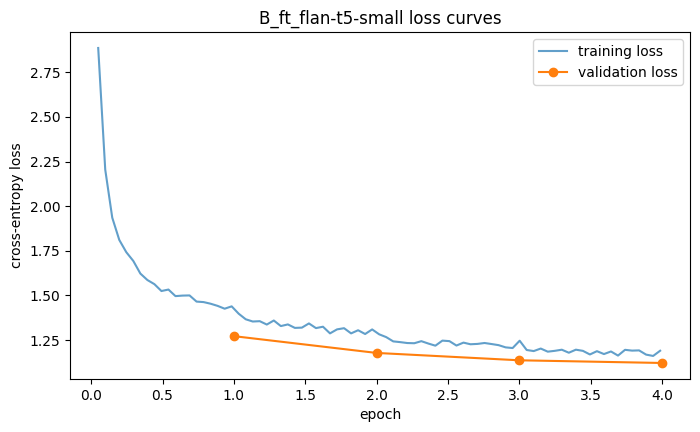

In [11]:
import matplotlib.pyplot as plt
hist = pd.DataFrame(trainer.state.log_history)
tr = hist.dropna(subset=["loss"])[["epoch", "loss"]]
va = hist.dropna(subset=["eval_loss"])[["epoch", "eval_loss"]]
display(va.reset_index(drop=True))

plt.figure(figsize=(8, 4.5))
plt.plot(tr.epoch, tr.loss, label="training loss", alpha=.7)
plt.plot(va.epoch, va.eval_loss, "o-", label="validation loss")
plt.xlabel("epoch"); plt.ylabel("cross-entropy loss"); plt.title(f"{RUN_NAME} loss curves"); plt.legend()
plt.savefig(os.path.join(sg.PLOTS_DIR, f"loss_curves_{RUN_NAME}.png"), dpi=130, bbox_inches="tight"); plt.show()
hist.to_csv(os.path.join(sg.RESULTS_DIR, f"train_log_{RUN_NAME}.csv"), index=False)

## 8. Held-out test loss
Computed once on the **test** split, which was never used for training or model selection.

In [12]:
test_metrics = trainer.evaluate(tok_ds["test"], metric_key_prefix="test")
best_val = trainer.state.best_metric
print(f"best validation loss: {best_val:.4f} (perplexity {np.exp(best_val):.2f})")
print(f"test loss:            {test_metrics['test_loss']:.4f} (perplexity {np.exp(test_metrics['test_loss']):.2f})")

[transformers] early stopping required metric_for_best_model, but did not find eval_loss so early stopping is disabled


Training Loss,Validation Loss,Epoch
1.190696,1.110538,4


best validation loss: 1.1222 (perplexity 3.07)
test loss:            1.1105 (perplexity 3.04)


## 9. Save the fine-tuned model
The folder contains everything the Django backend needs: weights (`model.safetensors`), `config.json`,
tokenizer files, plus `training_config.json` (prompt template, max lengths, decoding settings and the
hyper-parameters of this run).

In [13]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
trainer.save_model(OUTPUT_DIR)
tok.save_pretrained(OUTPUT_DIR)
trainer.state.save_to_json(os.path.join(OUTPUT_DIR, "trainer_state.json"))

training_config = {
    "run_name": RUN_NAME, "base_model": MODEL_NAME, "dataset_id": sg.DATASET_ID,
    "prompt_template": sg.PROMPT_TEMPLATE, "summary_template": sg.SUMMARY_TEMPLATE,
    "action_template": sg.ACTION_TEMPLATE,
    "max_input_len": MAX_IN, "max_target_len": MAX_OUT, "generation": sg.DEFAULT_GEN_KWARGS,
    "hyperparameters": HP, "effective_batch_size": HP["per_device_train_batch_size"] * HP["gradient_accumulation_steps"],
    "bf16": use_bf16, "seed": sg.SEED, "quick_run": QUICK_RUN,
    "train_examples": len(tok_ds["train"]), "val_examples": len(tok_ds["val"]), "test_examples": len(tok_ds["test"]),
    "epochs_completed": float(trainer.state.epoch), "best_checkpoint": trainer.state.best_model_checkpoint,
    "train_loss_avg": float(train_result.training_loss), "best_val_loss": float(best_val),
    "test_loss": float(test_metrics["test_loss"]), "train_minutes": round(train_minutes, 1),
    "parameters": n_params,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__, "python": platform.python_version()},
}
sg.save_json(training_config, os.path.join(OUTPUT_DIR, "training_config.json"))
sg.log_experiment(RUN_NAME, model=MODEL_NAME, epochs=float(trainer.state.epoch),
                  learning_rate=HP["learning_rate"], batch_size=training_config["effective_batch_size"],
                  grad_accum=HP["gradient_accumulation_steps"], max_input_len=MAX_IN, max_target_len=MAX_OUT,
                  train_loss=float(train_result.training_loss), val_loss=float(best_val),
                  test_loss=float(test_metrics["test_loss"]),
                  notes=f"Full fine-tuning; quick_run={QUICK_RUN}; {training_config['gpu']}")
print("Saved model to", OUTPUT_DIR, "→", sorted(os.listdir(OUTPUT_DIR)))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model to /content/drive/MyDrive/SupportGen/models/flan-t5-supportgen → ['config.json', 'generation_config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'trainer_state.json', 'training_args.bin', 'training_config.json']


/content/drive/MyDrive/SupportGen/supportgen_common.py:275: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([{"run_name": run_name, **fields}])], ignore_index=True)


## 10. Quick sanity check — generate replies for three unseen test tickets

In [14]:
import textwrap
ft = AutoModelForSeq2SeqLM.from_pretrained(OUTPUT_DIR).to(sg.get_device())
sample = test_df.sample(3, random_state=sg.SEED)
outs, _ = sg.generate_batch(ft, tok, [sg.build_prompt(s, b) for s, b in zip(sample.subject, sample.body)], MAX_IN, MAX_OUT)
for (_, r), o in zip(sample.iterrows(), outs):
    print("=" * 100); print("SUBJECT:", r.subject); print("TICKET:", textwrap.shorten(r.body, 300))
    print("\nREFERENCE:", textwrap.fill(r.answer, 100)); print("\nFINE-TUNED:", textwrap.fill(o, 100))

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


SUBJECT: Ensuring the Safety of Medical Data
TICKET: Requesting advice on securing medical data using Microsoft OneNote and Kaspersky Internet Security. Would like to know if these tools can protect sensitive medical information from unauthorized access. Could you provide guidance on setting up encryption and access controls to ensure the [...]

REFERENCE: Thank you for your concern about securing medical data. I am happy to provide guidance on the best
practices for using Microsoft OneNote and Kaspersky Internet Security. To protect sensitive medical
information from unauthorized access, I recommend setting up encryption and access controls. In
Microsoft OneNote, you can use password protection and encryption to secure your notebooks.
Additionally, Kaspersky Internet Security offers an extra layer of protection against malware and
unauthorized access. I will provide detailed information on how to configure these settings.

FINE-TUNED: We can provide guidance on securing medical data u

➡️ **Next:** `04_evaluate_model.ipynb` — full metric comparison of Model A vs Model B.

*(Optional Model D: set `MODEL_NAME = "google/flan-t5-base"` in section 1 and re-run this notebook.)*